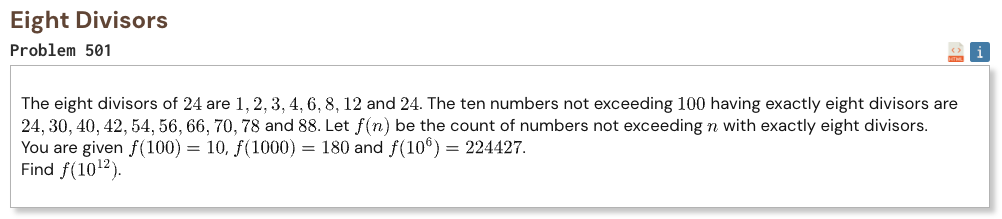

## Initial approach

- numbers with exactly eight divisors can only have three possible prime factor patterns
- count seventh powers of primes directly
- count products containing one cubed prime and one different prime
- count products of three distinct primes in increasing order
- use a sieve up to one million for the needed primes
- use Lehmer prime counting to count primes below large limits quickly
- add the three cases together

In [1]:
%%time

from functools import lru_cache
from math import isqrt

N = 10**12
LIMIT = 10**6

sieve = bytearray(b"\x01") * (LIMIT + 1)
sieve[0:2] = b"\x00\x00"

for p in range(2, isqrt(LIMIT) + 1):
    if sieve[p]:
        start = p * p
        sieve[start:LIMIT + 1:p] = b"\x00" * (
            (LIMIT - start) // p + 1
        )

primes = []
pi = [0] * (LIMIT + 1)
count = 0

for i in range(LIMIT + 1):
    if sieve[i]:
        primes.append(i)
        count += 1

    pi[i] = count

@lru_cache(None)
def phi(x, s):
    if s == 0:
        return x

    return phi(x, s - 1) - phi(x // primes[s - 1], s - 1)

@lru_cache(None)
def lehmer_pi(x):
    if x <= LIMIT:
        return pi[x]

    a = lehmer_pi(isqrt(isqrt(x)))
    b = lehmer_pi(isqrt(x))
    c = lehmer_pi(round(x ** (1 / 3)))

    result = phi(x, a) + ((b + a - 2) * (b - a + 1)) // 2

    for i in range(a, b):
        w = x // primes[i]
        result -= lehmer_pi(w)

        if i < c:
            limit = lehmer_pi(isqrt(w))

            for j in range(i, limit):
                result -= lehmer_pi(w // primes[j]) - j

    return result

result = 0

p = 2

while p**7 <= N:
    result += 1
    p = primes[pi[p]]

for p in primes:
    if p**3 * 2 > N:
        break

    limit = N // (p**3)
    result += lehmer_pi(limit)

    if p <= limit:
        result -= 1

for i, p in enumerate(primes):
    if p * primes[i + 1] * primes[i + 2] > N:
        break

    for j in range(i + 1, len(primes)):
        q = primes[j]

        if p * q * q > N:
            break

        limit = N // (p * q)

        if limit <= q:
            break

        result += lehmer_pi(limit) - (j + 1)

print("Result:", result)

Result: 197912312715
CPU times: user 41 s, sys: 887 ms, total: 41.9 s
Wall time: 42.7 s
